# Volatility Dynamics 02b — is the native 5m clock profile signal or noise?

Claude review (discussion **VD 010**). Module 02 measured an exact-UTC-slot profile of $\log r_t^2$ from about 16–17 finite observations per slot per asset. With $\operatorname{sd}(\log r^2)\approx 2.2$, the spread of 288 noisy slot medians is large even with **no** clock effect.

This notebook separates signal from noise at two resolutions (exact 5m slot, UTC hour):

1. **Rotation null** — rotate each UTC day's clock labels by an independent random circular offset (keeps within-day contiguity, so volatility clustering is preserved; destroys only a clock effect repeating across days); recompute the Module 02 amplitude $Q_{90}-Q_{10}$ of slot medians. A plain label shuffle is anti-conservative for hourly bins.
2. **Split-half reliability** — correlation of profiles estimated on even vs odd UTC days (Spearman–Brown corrected).
3. **Signal share** — $(\text{observed} - \text{null mean})/\text{observed}$.

Inputs: `state_time`, `underlying`, `return_5m` only. Outputs: `02b/`.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 300)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_clock_null as cn
START = os.getenv('VD2B_START', '').strip() or None
END = os.getenv('VD2B_END', '').strip() or None
ASSETS = [x.strip().upper() for x in os.getenv('VD2B_ASSETS', '').split(',') if x.strip()]
N_PERM = int(os.getenv('VD2B_N_PERM', '500'))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '02b'
OUT.mkdir(parents=True, exist_ok=True)
print('clock null engine', cn.VERSION, '| selftest:', cn.selftest())


clock null engine 0.2.0 | selftest: {'flat_not_detected': True, 'real_clock_detected': True, 'split_half': True}


In [2]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

def load_frame(columns, start=None, end=None, assets=None):
    cols = list(dict.fromkeys(['state_time', 'underlying', 'return_5m'] + list(columns)))
    where = []
    if start:
        ts = pd.Timestamp(start)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
    if end:
        ts = pd.Timestamp(end)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time < TIMESTAMPTZ '{(ts + pd.Timedelta(days=1)).isoformat()}'")
    if assets:
        where.append('underlying IN (' + ','.join(repr(x) for x in assets) + ')')
    sql = ('SELECT ' + ', '.join(qident(c) for c in cols) + ' FROM time_series_feature_state'
           + ('' if not where else ' WHERE ' + ' AND '.join(where)) + ' ORDER BY underlying, state_time')
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        df = con.execute(sql).df()
    finally:
        con.close()
    if df.empty:
        raise RuntimeError('No rows found.')
    df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
    if df.duplicated(['underlying', 'state_time']).any():
        raise RuntimeError('Duplicate asset/timestamp rows.')
    print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())} | {df.state_time.min()} -> {df.state_time.max()}')
    return df.reset_index(drop=True)

def schema_columns():
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        return con.execute('DESCRIBE time_series_feature_state').df()
    finally:
        con.close()

df = load_frame([], START, END, ASSETS)
panel = cn.prepare(df)


rows 42,336 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | 2026-09-19 08:00:00+00:00 -> 2026-10-10 07:55:00+00:00


In [3]:
t0 = time.time()
summary, profiles = cn.clock_null(panel, n_perm=N_PERM)
print(f'{N_PERM} permutations in {time.time()-t0:.1f}s')
display(summary.round(3))
display(summary.groupby('resolution')[['observed_amplitude_q90_q10','null_mean_amplitude','signal_share_of_amplitude','split_half_corr_even_odd_days','spearman_brown_reliability']].median().round(3))


500 permutations in 25.1s


,underlying,resolution,n_labels,median_obs_per_label,observed_amplitude_q90_q10,null_mean_amplitude,null_q95_amplitude,perm_p_value,excess_amplitude,signal_share_of_amplitude,pooled_log_variance_iqr,observed_amplitude_to_iqr,split_half_corr_even_odd_days,spearman_brown_reliability
0,AVAX,slot_5m,288,19.0,1.783,1.485,1.603,0.002,0.299,0.167,2.910,0.613,0.074,0.138
1,AVAX,hour,24,222.0,0.740,0.493,0.630,0.008,0.247,0.334,2.910,0.254,0.308,0.471
2,BTC,slot_5m,288,19.0,2.018,1.588,1.695,0.002,0.430,0.213,3.035,0.665,0.398,0.570
3,BTC,hour,24,222.0,1.176,0.600,0.796,0.002,0.577,0.490,3.035,0.388,0.811,0.896
4,ETH,slot_5m,288,19.0,2.082,1.542,1.680,0.002,0.540,0.259,2.999,0.694,0.293,0.453
5,ETH,hour,24,222.0,1.232,0.564,0.723,0.002,0.668,0.542,2.999,0.411,0.734,0.847
6,HYPE,slot_5m,288,19.0,1.805,1.505,1.633,0.002,0.300,0.166,2.803,0.644,0.163,0.280
7,HYPE,hour,24,222.0,1.101,0.538,0.717,0.002,0.564,0.512,2.803,0.393,0.556,0.715
8,SOL,slot_5m,288,19.0,1.824,1.471,1.591,0.002,0.353,0.193,2.841,0.642,0.145,0.254
9,SOL,hour,24,222.0,0.619,0.463,0.611,0.038,0.157,0.253,2.841,0.218,0.660,0.795


,observed_amplitude_q90_q10,null_mean_amplitude,signal_share_of_amplitude,split_half_corr_even_odd_days,spearman_brown_reliability
resolution,,,,,
hour,0.973,0.538,0.434,0.660,0.795
slot_5m,1.840,1.505,0.192,0.163,0.280


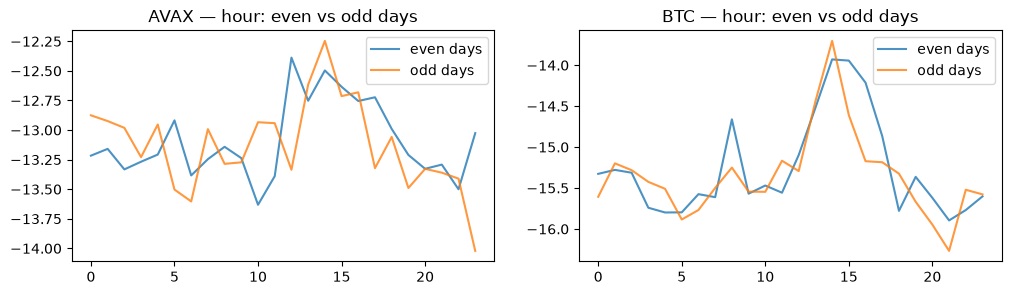

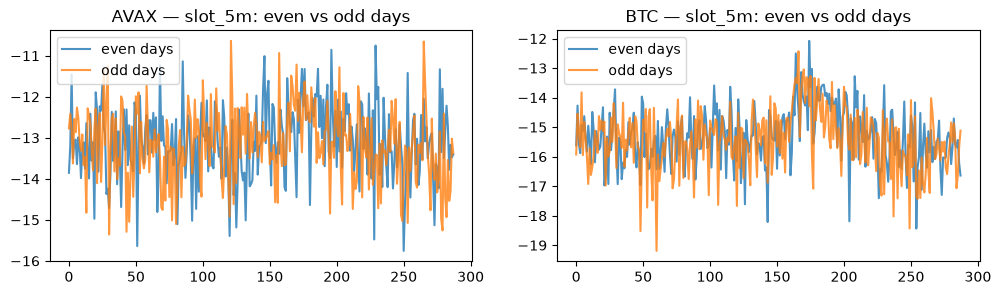

In [4]:
for res in ['hour', 'slot_5m']:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    for ax, a in zip(axes, sorted(profiles.underlying.unique())[:2]):
        g = profiles[(profiles.underlying == a) & (profiles.resolution == res)]
        ax.plot(g.label, g.median_even_days, label='even days', alpha=0.8)
        ax.plot(g.label, g.median_odd_days, label='odd days', alpha=0.8)
        ax.set_title(f'{a} — {res}: even vs odd days')
        ax.legend()
    plt.show()


In [5]:
summary.to_csv(OUT / '02b_clock_null_summary.csv', index=False)
profiles.to_csv(OUT / '02b_clock_profiles.csv', index=False)
meta = {
    'version': cn.VERSION, 'module': '02b_clock_null',
    'question': 'How much of the Module 02 exact-slot clock profile of log r^2 is sampling noise?',
    'null': 'per-day random circular rotation of clock labels', 'n_perm': N_PERM,
    'reliability': 'even vs odd UTC days, Spearman-Brown corrected',
    'start': START or 'earliest_available', 'end': END or 'latest_available',
    'n_rows': int(len(df)), 'first_time': str(df.state_time.min()), 'last_time': str(df.state_time.max()),
}
(OUT / '02b_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote', OUT)


wrote D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\02b
